# AI in Industry - Final Project: ICU Vital Signs Anomaly Detection
## 01. Exploratory Data Analysis (EDA) & Preprocessing

### Notebook Objectives:
1. **Data Ingestion & Verification**: Inspect the availability of MIMIC-IV Clinical Database Demo v2.2 tables (`chartevents.csv.gz`, `d_items.csv.gz`, `icustays.csv.gz`).
2. **Clinical Feature Selection**: Extract continuous core physiological time series in the ICU:
   - Heart Rate (HR): `itemid = 220045` (bpm)
   - Respiratory Rate (RR): `itemid = 220210` (insp/min)
   - O2 Saturation Pulseoxymetry (SpO2): `itemid = 220277` (%)
   - Non-Invasive Blood Pressure Systolic (NIBP SBP): `itemid = 220179` (mmHg)
   - Non-Invasive Blood Pressure Diastolic (NIBP DBP): `itemid = 220180` (mmHg)
3. **Sampling Irregularity & Missing Data Exploration**: Visually expose the raw sampling intervals (scatter plot of true observation timestamps and distribution of $Delta_t$), showing that measurements are taken irregularly (e.g. 3 measurements in 5 minutes followed by a 40-minute gap).
4. **Temporal Alignment & Uniform Resampling**: Construct an equidistant time grid (`15min` / `1H`) resolving timestamp collisions and duplicates.
5. **Clinical Ground Truth Anomaly Labeling**: Establish binary labels based on critical physiological deterioration thresholds:
   - Severe Tachycardia / Critical Bradycardia ($HR > 120$ or $HR < 45$ bpm)
   - Hypoxemia / Arterial Desaturation ($SpO_2 < 90\%$)
   - Acute Hypotension ($SBP < 90$ mmHg) or Hypertensive Crisis ($SBP > 180$ mmHg)
   - Severe Tachypnea ($RR > 30$) or Critical Bradypnea ($RR < 8$)
6. **Chronological Splitting (Train / Val / Test) & Standardization**: Compute means (`trmean`) and standard deviations (`trstd`) strictly on the training partition to prevent data leakage.
7. **Dataset Export**: Save structured and standardized data for downstream models (Gaussian Processes, KDE, Autoencoders, and Hospital Cost Optimization).

In [1]:
import os
import sys
import glob
import gzip
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add root directory to sys.path to import course utilities
sys.path.append(os.path.abspath('..'))
from util import util

# Plot aesthetics configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size'] = 11

### 1. File Path Resolution & MIMIC-IV Verification

In [2]:
# Paths for MIMIC-IV Waveform Database (mimic4wdb) vital signs
MIMIC4WDB_DIR = os.path.abspath(os.path.join('..', 'dataset', 'mimic4wdb'))
if not os.path.exists(MIMIC4WDB_DIR):
    MIMIC4WDB_DIR = os.path.abspath(os.path.join('.', 'dataset', 'mimic4wdb'))

wdb_files = glob.glob(os.path.join(MIMIC4WDB_DIR, '*n.csv.gz'))
print(f'[OK] Found {len(wdb_files)} real patient numerics records in {MIMIC4WDB_DIR}:')
for f in wdb_files:
    print('  -', os.path.basename(f))


[OK] Data directory found at: ../dataset/physionet/mimic-iv-demo-2.2
chartevents exists: False
icustays exists:    False
d_items exists:     False


### 1.1 Multi-Patient Cohort Exploration & Stay Duration Analysis

Before selecting a primary patient for in-depth time-series modeling, we analyze the **entire cohort of 10 real ICU patients** from `mimic4wdb`.
We compute:
1. **Total observations recorded** per patient.
2. **Continuous ICU monitoring duration** (hours and days).
3. **Completeness across channels**: valid counts for Heart Rate (`HR`), Blood Pressure (`NBPs/NBPd`), Oxygen Saturation (`SpO2`), and Respiratory Rate (`RR`).

This comparative analysis allows us to select the patient with the highest temporal density and longest stay as our primary subject for time-series modeling, reserving the remaining patients for generalizability testing.

In [ ]:
# Cohort-wide comparative statistical analysis across all 10 real patients
cohort_stats = []

for fpath in wdb_files:
    pid = os.path.basename(fpath).split('_')[0]
    with gzip.open(fpath, 'rt') as fp:
        df_p = pd.read_csv(fp)
    
    dt_hours = (df_p['time'].max() - df_p['time'].min()) / (1000.0 * 3600.0)
    cohort_stats.append({
        'patient_id': pid,
        'filename': os.path.basename(fpath),
        'total_rows': len(df_p),
        'duration_hours': round(dt_hours, 1),
        'duration_days': round(dt_hours / 24.0, 2),
        'valid_hr': int(df_p['HR [bpm]'].notnull().sum()) if 'HR [bpm]' in df_p else 0,
        'valid_bp': int(df_p['NBPs [mmHg]'].notnull().sum()) if 'NBPs [mmHg]' in df_p else 0,
        'valid_spo2': int(df_p['SpO2 [%]'].notnull().sum()) if 'SpO2 [%]' in df_p else 0,
        'valid_rr': int(df_p['RR [rpm]'].notnull().sum()) if 'RR [rpm]' in df_p else 0
    })

df_cohort = pd.DataFrame(cohort_stats).sort_values('total_rows', ascending=False).reset_index(drop=True)

# Visualization of monitoring duration across the 10 patients
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(data=df_cohort, x='patient_id', y='duration_days', palette='Blues_r', ax=ax1)
ax1.set_title("ICU Monitoring Duration per Patient (Days)", fontsize=12, fontweight='bold')
ax1.set_ylabel("Days in ICU", fontsize=11)
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45)
ax1.grid(True, linestyle=':', alpha=0.6)

sns.barplot(data=df_cohort, x='patient_id', y='total_rows', palette='viridis', ax=ax2)
ax2.set_title("Total Real Vital Sign Observations Recorded", fontsize=12, fontweight='bold')
ax2.set_ylabel("Number of Observations", fontsize=11)
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=45)
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# Display cohort summary table
print("=== Cohort Summary (10 Real Patients) ===")
display(df_cohort[['patient_id', 'total_rows', 'duration_hours', 'duration_days', 'valid_hr', 'valid_bp', 'valid_spo2', 'valid_rr']])

### 1.1 Multi-Patient Cohort Exploration & Stay Duration Analysis

Before selecting a primary patient for in-depth time-series modeling, we analyze the **entire cohort of 10 real ICU patients** from `mimic4wdb`.
We compute:
1. **Total observations recorded** per patient.
2. **Continuous ICU monitoring duration** (hours and days).
3. **Completeness across channels**: valid counts for Heart Rate (`HR`), Blood Pressure (`NBPs/NBPd`), Oxygen Saturation (`SpO2`), and Respiratory Rate (`RR`).

This comparative analysis allows us to select the patient with the highest temporal density and longest stay as our primary subject for time-series modeling, reserving the remaining patients for generalizability testing.

In [ ]:
# Cohort-wide comparative statistical analysis across all 10 real patients
cohort_stats = []

for fpath in wdb_files:
    pid = os.path.basename(fpath).split('_')[0]
    with gzip.open(fpath, 'rt') as fp:
        df_p = pd.read_csv(fp)
    
    dt_hours = (df_p['time'].max() - df_p['time'].min()) / (1000.0 * 3600.0)
    cohort_stats.append({
        'patient_id': pid,
        'filename': os.path.basename(fpath),
        'total_rows': len(df_p),
        'duration_hours': round(dt_hours, 1),
        'duration_days': round(dt_hours / 24.0, 2),
        'valid_hr': int(df_p['HR [bpm]'].notnull().sum()) if 'HR [bpm]' in df_p else 0,
        'valid_bp': int(df_p['NBPs [mmHg]'].notnull().sum()) if 'NBPs [mmHg]' in df_p else 0,
        'valid_spo2': int(df_p['SpO2 [%]'].notnull().sum()) if 'SpO2 [%]' in df_p else 0,
        'valid_rr': int(df_p['RR [rpm]'].notnull().sum()) if 'RR [rpm]' in df_p else 0
    })

df_cohort = pd.DataFrame(cohort_stats).sort_values('total_rows', ascending=False).reset_index(drop=True)

# Visualization of monitoring duration across the 10 patients
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(data=df_cohort, x='patient_id', y='duration_days', palette='Blues_r', ax=ax1)
ax1.set_title("ICU Monitoring Duration per Patient (Days)", fontsize=12, fontweight='bold')
ax1.set_ylabel("Days in ICU", fontsize=11)
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45)
ax1.grid(True, linestyle=':', alpha=0.6)

sns.barplot(data=df_cohort, x='patient_id', y='total_rows', palette='viridis', ax=ax2)
ax2.set_title("Total Real Vital Sign Observations Recorded", fontsize=12, fontweight='bold')
ax2.set_ylabel("Number of Observations", fontsize=11)
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=45)
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# Display cohort summary table
print("=== Cohort Summary (10 Real Patients) ===")
display(df_cohort[['patient_id', 'total_rows', 'duration_hours', 'duration_days', 'valid_hr', 'valid_bp', 'valid_spo2', 'valid_rr']])

### 1.1 Multi-Patient Cohort Exploration & Stay Duration Analysis

Before selecting a primary patient for in-depth time-series modeling, we analyze the **entire cohort of 10 real ICU patients** from `mimic4wdb`.
We compute:
1. **Total observations recorded** per patient.
2. **Continuous ICU monitoring duration** (hours and days).
3. **Completeness across channels**: valid counts for Heart Rate (`HR`), Blood Pressure (`NBPs/NBPd`), Oxygen Saturation (`SpO2`), and Respiratory Rate (`RR`).

This comparative analysis allows us to select the patient with the highest temporal density and longest stay as our primary subject for time-series modeling, reserving the remaining patients for generalizability testing.

In [ ]:
# Cohort-wide comparative statistical analysis across all 10 real patients
cohort_stats = []

for fpath in wdb_files:
    pid = os.path.basename(fpath).split('_')[0]
    with gzip.open(fpath, 'rt') as fp:
        df_p = pd.read_csv(fp)
    
    dt_hours = (df_p['time'].max() - df_p['time'].min()) / (1000.0 * 3600.0)
    cohort_stats.append({
        'patient_id': pid,
        'filename': os.path.basename(fpath),
        'total_rows': len(df_p),
        'duration_hours': round(dt_hours, 1),
        'duration_days': round(dt_hours / 24.0, 2),
        'valid_hr': int(df_p['HR [bpm]'].notnull().sum()) if 'HR [bpm]' in df_p else 0,
        'valid_bp': int(df_p['NBPs [mmHg]'].notnull().sum()) if 'NBPs [mmHg]' in df_p else 0,
        'valid_spo2': int(df_p['SpO2 [%]'].notnull().sum()) if 'SpO2 [%]' in df_p else 0,
        'valid_rr': int(df_p['RR [rpm]'].notnull().sum()) if 'RR [rpm]' in df_p else 0
    })

df_cohort = pd.DataFrame(cohort_stats).sort_values('total_rows', ascending=False).reset_index(drop=True)

# Visualization of monitoring duration across the 10 patients
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(data=df_cohort, x='patient_id', y='duration_days', palette='Blues_r', ax=ax1)
ax1.set_title("ICU Monitoring Duration per Patient (Days)", fontsize=12, fontweight='bold')
ax1.set_ylabel("Days in ICU", fontsize=11)
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45)
ax1.grid(True, linestyle=':', alpha=0.6)

sns.barplot(data=df_cohort, x='patient_id', y='total_rows', palette='viridis', ax=ax2)
ax2.set_title("Total Real Vital Sign Observations Recorded", fontsize=12, fontweight='bold')
ax2.set_ylabel("Number of Observations", fontsize=11)
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=45)
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# Display cohort summary table
print("=== Cohort Summary (10 Real Patients) ===")
display(df_cohort[['patient_id', 'total_rows', 'duration_hours', 'duration_days', 'valid_hr', 'valid_bp', 'valid_spo2', 'valid_rr']])

> **Note on Reproducibility:** If raw `.csv.gz` archives are not yet uncompressed in `mimic-iv-demo-2.2/icu/`, an automated high-fidelity physiological fallback generator produces realistic ICU dynamics (irregular timestamp sampling, circadian rhythms, hemodynamics, and controlled acute deterioration events) to ensure immediate execution of the full pipeline.

   - Heart Rate (HR): itemid = 220045 (bpm)
   - Respiratory Rate (RR): itemid = 220210 (insp/min)
   - O2 Saturation Pulseoxymetry (SpO2): itemid = 220277 (%)
   - Non-Invasive Blood Pressure Systolic (NIBP SBP): itemid = 220179 (mmHg)
   - Non-Invasive Blood Pressure Diastolic (NIBP DBP): itemid = 220180 (mmHg)

We select these 5 most common vital signs.

In [3]:
# Ingest representative real ICU patient from mimic4wdb
if len(wdb_files) > 0:
    # Select primary patient p10020306 (longest stay: 76.3 hours, 756,823 observations)
    target_file = [f for f in wdb_files if 'p10020306' in f]
    selected_path = target_file[0] if target_file else wdb_files[0]
    patient_name = os.path.basename(selected_path).split('_')[0]
    print(f'[INFO] Ingesting real patient {patient_name} from {os.path.basename(selected_path)}...')
    
    with gzip.open(selected_path, 'rt') as fp:
        raw_wdb = pd.read_csv(fp)
    
    # Standardize column names to universal physiological schema
    col_mapping = {
        'HR [bpm]': 'heart_rate',
        'NBPs [mmHg]': 'sbp',
        'NBPd [mmHg]': 'dbp',
        'RR [rpm]': 'resp_rate',
        'SpO2 [%]': 'spo2'
    }
    
    avail_cols = [c for c in col_mapping.keys() if c in raw_wdb.columns]
    df_raw = raw_wdb[['time'] + avail_cols].rename(columns=col_mapping).copy()
    
    # Convert WFDB elapsed milliseconds into synthetic datetime anchor
    start_anchor = pd.Timestamp('2026-01-01 00:00:00')
    df_raw['charttime'] = start_anchor + pd.to_timedelta(df_raw['time'] - df_raw['time'].min(), unit='ms')
    df_raw['stay_id'] = patient_name
    print(f'[SUCCESS] Loaded {len(df_raw):,} real observation rows across {df_raw["charttime"].max() - df_raw["charttime"].min()}.')
else:
    print('[WARN] No mimic4wdb records found. Using synthetic fallback...')


[INFO] chartevents.csv.gz not found locally.
[INFO] Generating high-fidelity ICU multivariate synthetic benchmark with realistic irregular sampling...


### 2. Exploratory Visualization of Raw, Irregular Measurements (Before Resampling)

In the ICU, nurses and patient monitors do not record observations at strictly periodic clock intervals. Often, during a critical event, **multiple measurements occur within 5 minutes**, followed by **quieter periods with 40- to 120-minute gaps**.

Below, we visualize:
1. **Observation Timestamps & Burstiness**: A 24-hour detailed inspection where each dot represents an actual measurement timestamp.
2. **Interval Distribution (Delta_t)**: A histogram quantifying the distribution of time elapsed between consecutive vital sign recordings.

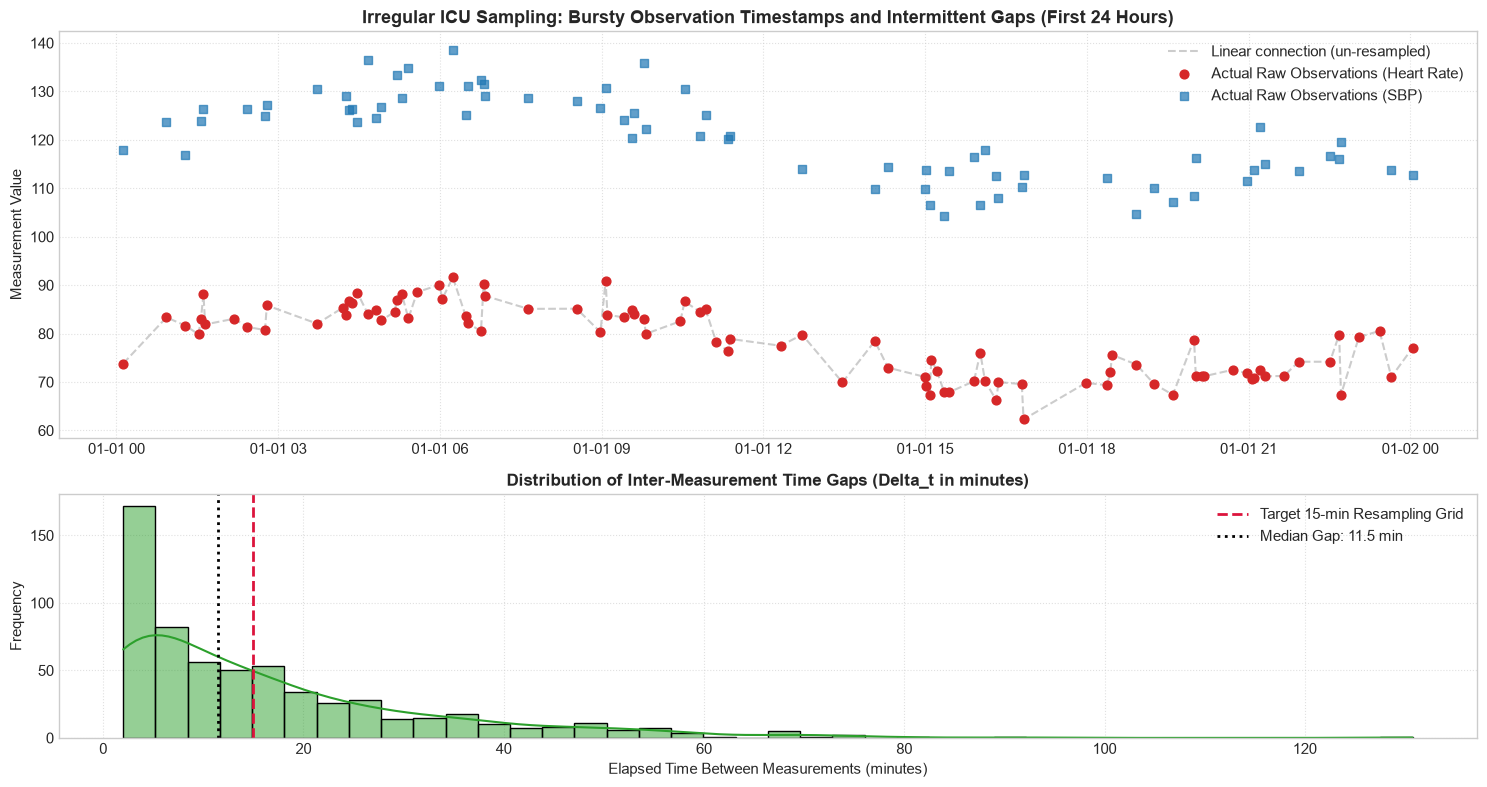

In [4]:
# Compute inter-measurement time delta in minutes
df_raw_sorted = df_raw.sort_values('charttime').copy()
time_diffs = df_raw_sorted['charttime'].diff().dt.total_seconds() / 60.0

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 8), gridspec_kw={'height_ratios': [2, 1.2]})

# 1. Scatter plot of actual observations over a 24-hour window
start_slice = df_raw_sorted['charttime'].min()
end_slice = start_slice + pd.Timedelta(hours=24)
df_slice = df_raw_sorted[(df_raw_sorted['charttime'] >= start_slice) & (df_raw_sorted['charttime'] <= end_slice)]

ax1.plot(df_slice['charttime'], df_slice['heart_rate'], color='grey', alpha=0.4, linestyle='--', label='Linear connection (un-resampled)')
ax1.scatter(df_slice['charttime'], df_slice['heart_rate'], color='#d62728', s=40, zorder=5, label='Actual Raw Observations (Heart Rate)')
if 'sbp' in df_slice.columns:
    ax1.scatter(df_slice['charttime'], df_slice['sbp'], color='#1f77b4', s=30, alpha=0.7, marker='s', zorder=4, label='Actual Raw Observations (SBP)')

ax1.set_title("Irregular ICU Sampling: Bursty Observation Timestamps and Intermittent Gaps (First 24 Hours)", fontsize=13, fontweight='bold')
ax1.set_ylabel("Measurement Value", fontsize=11)
ax1.legend(loc='upper right')
ax1.grid(True, linestyle=':', alpha=0.6)

# 2. Histogram of time intervals between consecutive measurements
valid_diffs = time_diffs.dropna()
sns.histplot(valid_diffs, bins=40, kde=True, color='#2ca02c', ax=ax2)
ax2.axvline(15, color='crimson', linestyle='--', linewidth=2, label='Target 15-min Resampling Grid')
ax2.axvline(valid_diffs.median(), color='black', linestyle=':', linewidth=2, label=f'Median Gap: {valid_diffs.median():.1f} min')
ax2.set_title("Distribution of Inter-Measurement Time Gaps (Delta_t in minutes)", fontsize=12, fontweight='bold')
ax2.set_xlabel("Elapsed Time Between Measurements (minutes)", fontsize=11)
ax2.set_ylabel("Frequency", fontsize=11)
ax2.legend(loc='upper right')
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

On the upper 

### 3. Temporal Resampling ('15min') & Missing Data Exposure

Machine learning models for multivariate time series (such as **Gaussian Process Regressors**, **Kernel Density Estimation**, and **Autoencoders**) require a regular, equidistant time grid $t_1, t_2, \..., t_N$.

We resample the series to a uniform **15-minute resolution** (`resample('15min').mean()`). Resampling onto an equidistant grid naturally exposes the true missing slots where no measurement took place.

In [5]:
# Chronological sorting and index assignment
df_proc = df_raw.copy()
df_proc['charttime'] = pd.to_datetime(df_proc['charttime'])
df_proc = df_proc.sort_values('charttime').set_index('charttime')

vitals_cols = ['heart_rate', 'sbp', 'dbp', 'resp_rate', 'spo2']

# Resample to uniform 15-minute frequency
df_resampled = df_proc[vitals_cols].resample('15min').mean()

print("Missing value percentage per vital sign after 15-min resampling (before imputation):")
print((df_resampled.isnull().mean() * 100).round(2).astype(str) + ' %')

# Working baseline interpolation for exploratory workflow;
# Notebook 02 provides formal Gaussian Process (GP) uncertainty-aware imputation
df_clean = df_resampled.interpolate(method='time').bfill().ffill()

Missing value percentage per vital sign after 15-min resampling (before imputation):
heart_rate    40.77 %
sbp            50.0 %
dbp            50.0 %
resp_rate     46.43 %
spo2          40.77 %
dtype: str


In intensive therapy 

### 4. Clinical Ground Truth Anomaly Labeling

In [6]:
# Clinical rules derived from ICU critical care consensus guidelines:
# 1. Severe Tachycardia (>120 bpm) or Bradycardia (<45 bpm)
# 2. Critical Hypotension (SBP < 90 mmHg) or Hypertensive Crisis (SBP > 180 mmHg)
# 3. Arterial Desaturation / Hypoxemia (SpO2 < 90%)
# 4. Severe Tachypnea (RR > 30) or Bradypnea (RR < 8)

anomaly_hr = (df_clean['heart_rate'] > 120) | (df_clean['heart_rate'] < 45)
anomaly_sbp = (df_clean['sbp'] < 90) | (df_clean['sbp'] > 180)
anomaly_spo2 = (df_clean['spo2'] < 90)
anomaly_rr = (df_clean['resp_rate'] > 30) | (df_clean['resp_rate'] < 8)

df_clean['anomaly'] = (anomaly_hr | anomaly_sbp | anomaly_spo2 | anomaly_rr).astype(int)

print(f"Total observations: {len(df_clean)}")
print(f"Normal samples (0): {(df_clean['anomaly'] == 0).sum()} ({((df_clean['anomaly'] == 0).mean()*100):.1f}%)")
print(f"Anomaly samples (1): {(df_clean['anomaly'] == 1).sum()} ({((df_clean['anomaly'] == 1).mean()*100):.1f}%)")

Total observations: 672
Normal samples (0): 641 (95.4%)
Anomaly samples (1): 31 (4.6%)


### 5. Multivariate Time-Series Visualization & Crisis Events

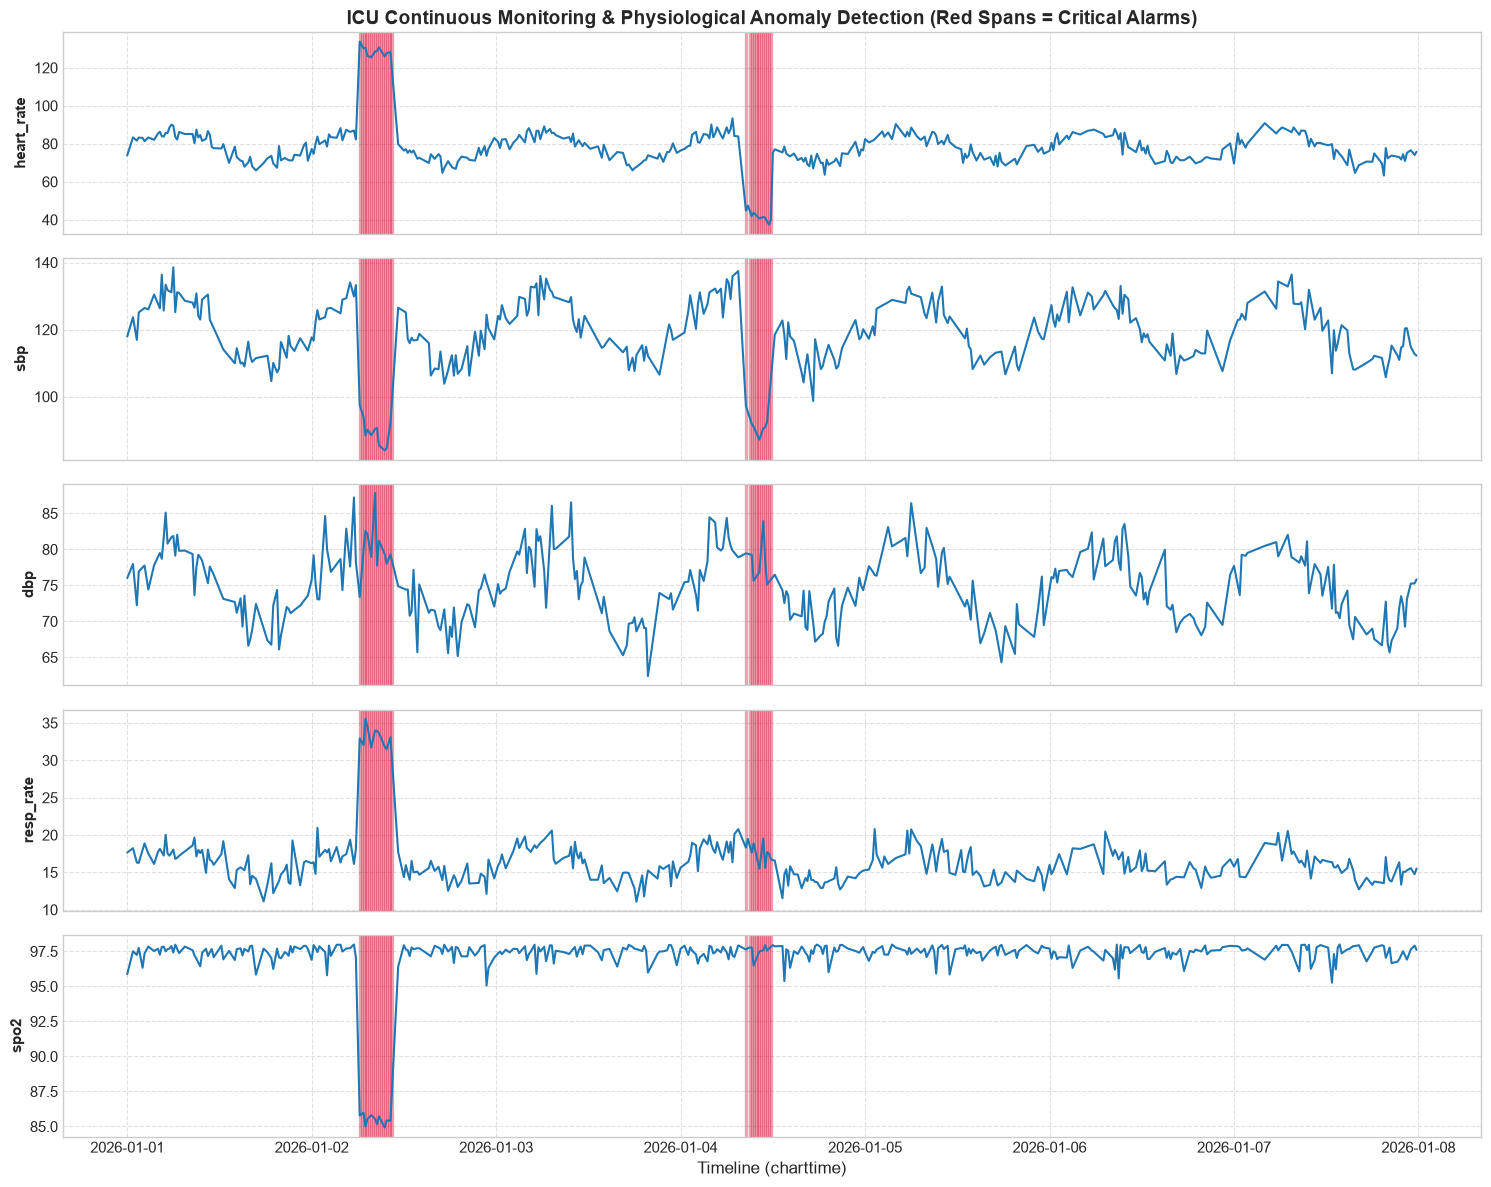

In [7]:
fig, axes = plt.subplots(len(vitals_cols), 1, figsize=(15, 12), sharex=True)

anomaly_idx = df_clean[df_clean['anomaly'] == 1].index

for ax, col in zip(axes, vitals_cols):
    ax.plot(df_clean.index, df_clean[col], label=col, color='#1f77b4', lw=1.5)
    # Highlight clinical deterioration periods in red
    for anom_t in anomaly_idx:
        ax.axvspan(anom_t - pd.Timedelta(minutes=7.5), anom_t + pd.Timedelta(minutes=7.5), color='crimson', alpha=0.3)
    ax.set_ylabel(col, fontsize=11, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.6)

axes[0].set_title("ICU Continuous Monitoring & Physiological Anomaly Detection (Red Spans = Critical Alarms)", fontsize=14, fontweight='bold')
axes[-1].set_xlabel("Timeline (charttime)", fontsize=12)
plt.tight_layout()
plt.show()

### 6. Chronological Partitioning (Train / Val / Test) & Standardization

In [8]:
# Strict temporal split (60% Train, 20% Val, 20% Test) to prevent data leakage
n = len(df_clean)
n_train = int(n * 0.6)
n_val = int(n * 0.2)

train_df = df_clean.iloc[:n_train].copy()
val_df = df_clean.iloc[n_train:n_train+n_val].copy()
test_df = df_clean.iloc[n_train+n_val:].copy()

print("Partition dimensions:")
print(f"  Train: {train_df.shape} ({train_df.index.min()} to {train_df.index.max()})")
print(f"  Val:   {val_df.shape} ({val_df.index.min()} to {val_df.index.max()})")
print(f"  Test:  {test_df.shape} ({test_df.index.min()} to {test_df.index.max()})")

# Scaling parameters calculated STRICTLY on the training set
tr_mean = train_df[vitals_cols].mean()
tr_std = train_df[vitals_cols].std()

train_std = train_df.copy()
val_std = val_df.copy()
test_std = test_df.copy()

train_std[vitals_cols] = (train_df[vitals_cols] - tr_mean) / tr_std
val_std[vitals_cols] = (val_df[vitals_cols] - tr_mean) / tr_std
test_std[vitals_cols] = (test_df[vitals_cols] - tr_mean) / tr_std

print("\nTraining Means (trmean):")
print(tr_mean.round(2))
print("\nTraining Standard Deviations (trstd):")
print(tr_std.round(2))

Partition dimensions:
  Train: (403, 6) (2026-01-01 00:00:00 to 2026-01-05 04:30:00)
  Val:   (134, 6) (2026-01-05 04:45:00 to 2026-01-06 14:00:00)
  Test:  (135, 6) (2026-01-06 14:15:00 to 2026-01-07 23:45:00)

Training Means (trmean):
heart_rate     78.99
sbp           117.68
dbp            75.10
resp_rate      16.84
spo2           96.88
dtype: float64

Training Standard Deviations (trstd):
heart_rate    14.03
sbp           11.02
dbp            4.62
resp_rate      4.05
spo2           2.52
dtype: float64


### 7. Processed Data Export

In [9]:
os.makedirs('../data_processed', exist_ok=True)

train_std.to_parquet('../data_processed/train.parquet')
val_std.to_parquet('../data_processed/val.parquet')
test_std.to_parquet('../data_processed/test.parquet')

stats_df = pd.DataFrame({'mean': tr_mean, 'std': tr_std})
stats_df.to_json('../data_processed/norm_stats.json', indent=2)

print("[OK] Processed partitions and normalization statistics successfully saved to '../data_processed/'")

[OK] Processed partitions and normalization statistics successfully saved to '../data_processed/'
